# Optical proximity correction (OPC)

Near the resolution limit the printed shape of a feature depends on its
neighbourhood: isolated lines print at another size than dense ones, line
ends pull back, corners round. **Optical proximity correction** changes the
mask so that the printed edges land on the design (the *target*).

This notebook builds OPC from the pieces of `pyoptics.litho`, on Manhattan
polygons (edges along x and y), with a threshold resist model:

1. **Manhattan polygons as masks**: `MaskLayout.from_polygons()` turns any
   set of rectilinear polygons into an exact union of rectangles, so the
   diffraction orders stay analytic (no pixelated mask).
2. **Rule-based OPC**: a bias table through pitch (`opc.bias_table()`).
3. **Forbidden pitches and SRAFs**: depth of focus through pitch, and
   sub-resolution assist features (`opc.insert_srafs()`, `opc.sraf_margin()`).
4. **Model-based OPC**: edges cut into fragments, edge placement errors
   (EPE) at sites, and the iteration that moves the fragments
   (`opc.FragmentedLayout`, `opc.edge_placement_errors()`, `opc.model_opc()`):
   hammerheads, serifs and the corner rounding that remains.
5. **Speed**: Abbe against the Hopkins TCC and its SOCS kernels.
6. **Through focus**: OPC is done at one focus and dose.

Setup: ArF water immersion, NA 1.35, 6 % attenuated PSM (thin mask),
threshold 0.3 of the open frame; off-axis illumination with TE (azimuthal)
polarization for lines, conventional illumination for contacts. The dose
is anchored on a simple pattern (lines or a contact array) printing at
size.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle

from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask
from pyoptics.litho import hopkins, opc

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

projector = Projector(1.35, 193.0, n=1.437)
stack = ThinMask.att_psm()
THRESHOLD = 0.3


def rect(x0, y0, x1, y1):
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]


def draw(ax, polygons, **kwargs):
    for P in polygons:
        ax.add_patch(Polygon(P, closed=True, **kwargs))


def frame(ax, layout, title):
    ax.set_xlim(-layout.pitch_x/2, layout.pitch_x/2)
    ax.set_ylim(-layout.pitch_y/2, layout.pitch_y/2)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x [nm]")

## 1. Manhattan polygons as masks

A polygon is a list of vertices; its edges must be parallel to x or y.
`from_polygons()` orients the polygons counterclockwise, merges overlapping
ones and cuts the union into non-overlapping rectangles on the grid of all
vertex coordinates. The Fourier coefficients of the mask are then sums of
products of sinc functions, as for the built-in layouts. The polygons fill
one period of a periodic mask; with periods of several $\lambda/\mathrm{NA}$
the neighbours hardly interact.

Four clips, with 50 nm lines and 80 nm contacts, each in its own period:

In [2]:
clips = {
    "tip to tip": MaskLayout.from_polygons(200, 500, [rect(-25, -215, 25, -35), rect(-25, 35, 25, 215)]),
    "L": MaskLayout.from_polygons(400, 400, [[(-150, -150), (100, -150), (100, -100), (-100, -100),
                                              (-100, 150), (-150, 150)]]),
    "T": MaskLayout.from_polygons(400, 400, [[(-150, -25), (150, -25), (150, 25), (25, 25), (25, 150),
                                              (-25, 150), (-25, 25), (-150, 25)]]),
    "contacts": MaskLayout.from_polygons(400, 400, [rect(-120, -40, -40, 40), rect(40, -100, 120, 100)],
                                         tone="dark"),
}
for name, L in clips.items():
    print("{:10s} {} polygons -> {} rectangles, period {} x {} nm, tone {}".format(
        name, len(L.polygons), len(L.features), L.pitch_x, L.pitch_y, L.tone))

tip to tip 2 polygons -> 2 rectangles, period 200 x 500 nm, tone clear
L          1 polygons -> 2 rectangles, period 400 x 400 nm, tone clear
T          1 polygons -> 2 rectangles, period 400 x 400 nm, tone clear
contacts   2 polygons -> 2 rectangles, period 400 x 400 nm, tone dark


The L shape as rectangles, and the transmission sampled from them:

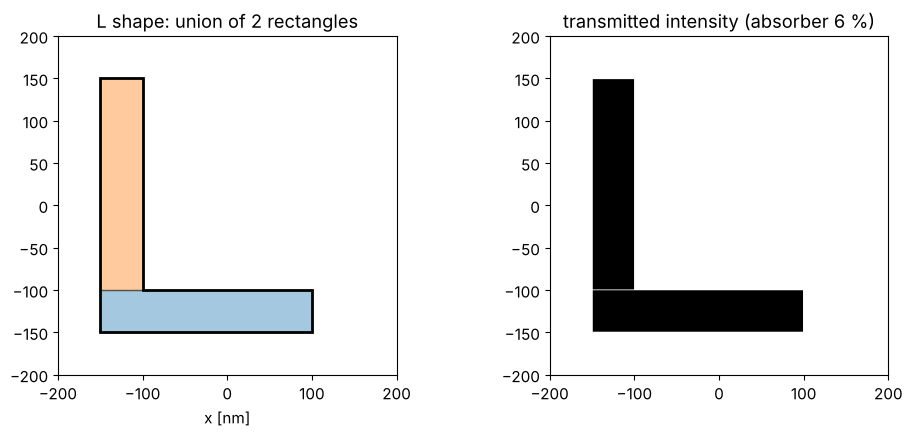

In [3]:
L = clips["L"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for k, (x0, y0, a, b) in enumerate(L.features):
    axs[0].add_patch(Rectangle((x0 - a/2, y0 - b/2), a, b, fc="C{}".format(k), alpha=0.4, ec="k"))
draw(axs[0], L.polygons, fill=False, ec="k", lw=2)
frame(axs[0], L, "L shape: union of {} rectangles".format(len(L.features)))
x = np.linspace(-200, 200, 401)
axs[1].imshow(np.abs(L.transmission(x, x, t_absorber=stack.t_absorber))**2, origin="lower",
              extent=(-200, 200, -200, 200), cmap="gray")
axs[1].set_title("transmitted intensity (absorber 6 %)")
plt.tight_layout()

### What prints without OPC

Images of one period on a 2 nm grid (Hopkins, see section 5) and the
printed contour at the threshold. The dose prints semi-dense lines (50 nm
at 200 nm pitch) at size, for the contacts a square array of 80 nm contacts
at 400 nm pitch (with conventional illumination, $\sigma = 0.5$). `model_opc(max_iter=0)` images the uncorrected target and
returns the EPEs at the sites (section 4).

dose (lines) = 0.799, dose (contacts) = 1.443


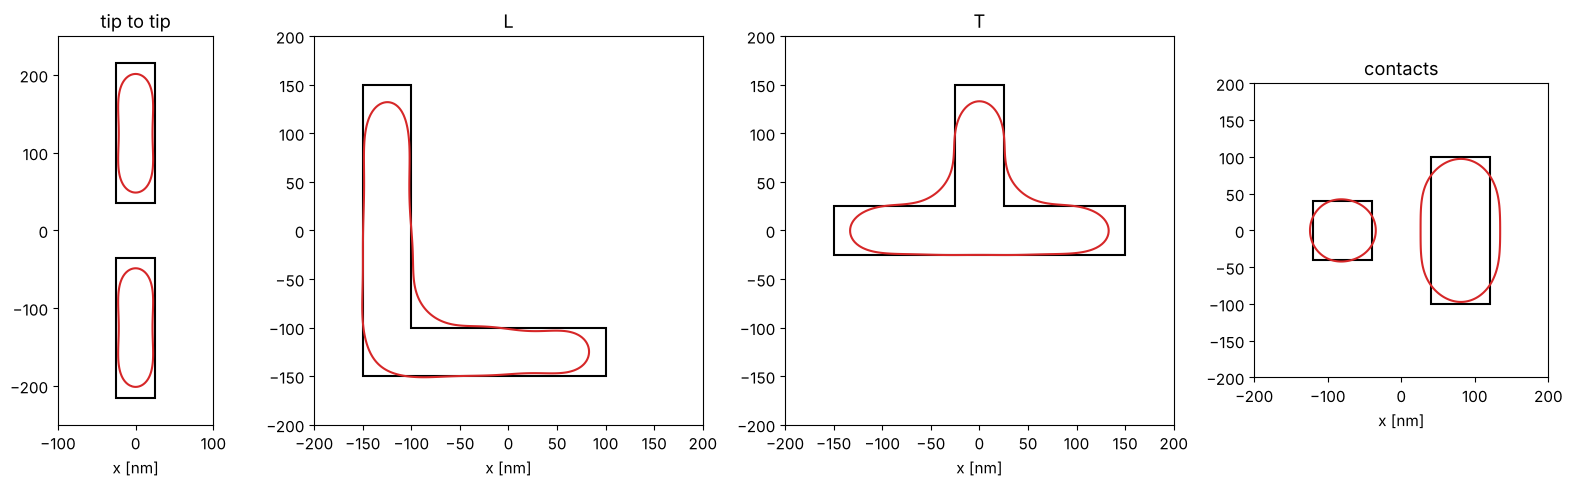

In [4]:
annular = Illumination.annular(0.9, 0.6, n_samples=11, polarization="TE")
conventional = Illumination.conventional(0.5, n_samples=11, polarization="unpolarized")
sim_lines = LithoSimulation(MaskLayout.lines_spaces(200, 50), stack, annular, projector)
sim_contacts = LithoSimulation(MaskLayout.contact_holes(400, 80), stack, conventional, projector)
dose_lines = sim_lines.dose_to_size(50, THRESHOLD)
dose_contacts = sim_contacts.dose_to_size(80, THRESHOLD)
print("dose (lines) = {:.3f}, dose (contacts) = {:.3f}".format(dose_lines, dose_contacts))

sims = {name: (sim_contacts if L.tone == "dark" else sim_lines).with_(layout=L) for name, L in clips.items()}
doses = {name: dose_contacts if L.tone == "dark" else dose_lines for name, L in clips.items()}
before = {name: opc.model_opc(sims[name], dose=doses[name], max_iter=0) for name in clips}

fig, axs = plt.subplots(1, 4, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 4, 4, 3]})
for ax, (name, r) in zip(axs, before.items()):
    draw(ax, clips[name].polygons, fill=False, ec="k", lw=1.5)
    ax.contour(r.x, r.y, r.image, [THRESHOLD], colors="C3")
    frame(ax, clips[name], name)
plt.tight_layout()

In [5]:
r = before["tip to tip"]
ends = r.fragments.sites[:, 0] == 0
print("tip to tip: line end pull back {:.1f} nm (gap {:.0f} nm instead of 70 nm)".format(
    -r.epe[ends].mean(), 70 - 2*r.epe[ends].mean()))
print("(an EPE of 30 nm is the search range: no printed edge within 30 nm of the site)")
for name, r in before.items():
    print("{:10s} max |EPE| = {:5.1f} nm, RMS EPE = {:4.1f} nm".format(name, *r.history[0]))

tip to tip: line end pull back 13.7 nm (gap 97 nm instead of 70 nm)
(an EPE of 30 nm is the search range: no printed edge within 30 nm of the site)
tip to tip max |EPE| =  30.0 nm, RMS EPE = 18.0 nm
L          max |EPE| =  30.0 nm, RMS EPE = 15.1 nm
T          max |EPE| =  30.0 nm, RMS EPE = 17.7 nm
contacts   max |EPE| =  14.9 nm, RMS EPE =  9.2 nm


Line ends pull back (about 14 nm each, the 70 nm gap prints almost
100 nm wide), corners round, the inner corners of the L and the T fill in,
the free ends of the L and the T arms shorten. The square contact prints
round, the bar contact too wide and a little short. Rules and models fix what can be fixed.

## 2. Rule-based OPC: bias through pitch

The simplest correction: lines get a mask bias that depends on the space to
their neighbours. `bias_table()` anchors the dose on one pitch (printing at
size without bias) and finds, for every pitch, the mask CD that prints the
target CD at that dose (root finding on the threshold CD of
`LithoSimulation.cd()`).

For 45 nm lines with a dipole optimized for the dense pitch (100 nm):

bias table: 0.4 s, dose 1.099


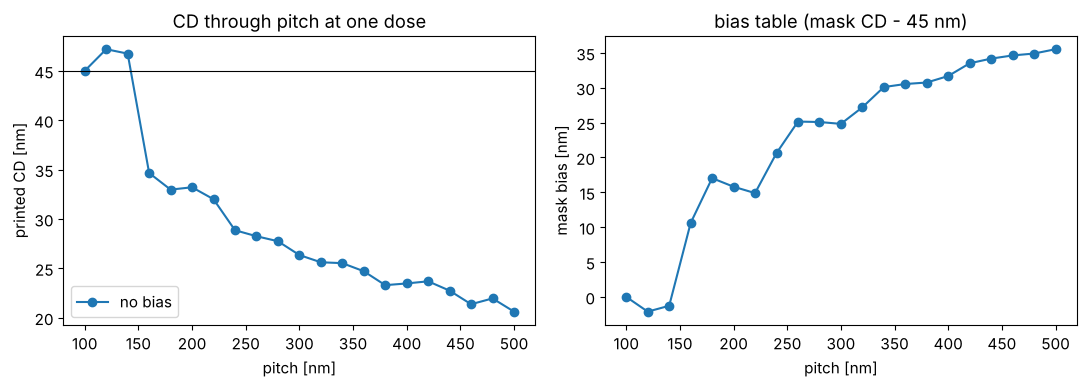

In [6]:
dipole = Illumination.dipole(0.9, 0.7, n_samples=15, polarization="TE")
lines = LithoSimulation(MaskLayout.lines_spaces(100, 45), stack, dipole, projector)
pitches = np.arange(100, 501, 20)
t0 = time.time()
bias, dose_dipole = opc.bias_table(lines, pitches, 45.0)
print("bias table: {:.1f} s, dose {:.3f}".format(time.time() - t0, dose_dipole))
cd_nobias = [lines.with_(layout=MaskLayout.lines_spaces(p, 45)).cd(THRESHOLD, dose_dipole) for p in pitches]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(pitches, cd_nobias, "o-", label="no bias")
axs[0].axhline(45, color="k", lw=0.8)
axs[0].set_xlabel("pitch [nm]"), axs[0].set_ylabel("printed CD [nm]")
axs[0].set_title("CD through pitch at one dose"), axs[0].legend()
axs[1].plot(pitches, bias, "o-")
axs[1].set_xlabel("pitch [nm]"), axs[1].set_ylabel("mask bias [nm]")
axs[1].set_title("bias table (mask CD - 45 nm)")
plt.tight_layout()

Without bias the isolated lines print much too thin at the dose of the
dense ones (with a clear field, more light reaches the line from the open
area around it); the table grows to about +35 nm at 500 nm pitch, so the
mask line is almost twice as wide as the target. Note the non-monotonic
part around 120 to 160 nm pitch: there the bias changes sign, the pitch
where the dipole poles stop helping. A real rule deck is such a table (in
practice in width and space), applied to every edge pair of the layout;
it handles 1D situations but not line ends or corners.

## 3. Forbidden pitches and SRAFs

The bias puts every pitch on size at best focus, but the **depth of focus**
(DOF: focus range with the CD within ±10 % at the common dose) still
depends on the pitch. Off-axis illumination tuned to the dense pitch gives
good DOF there and poor DOF at pitches where the diffraction orders fall on
the wrong side of the pupil: the **forbidden pitches**.

dipole {np.int64(100): np.float64(240.0), np.int64(120): np.float64(100.0), np.int64(140): np.float64(60.0), np.int64(160): np.float64(90.0), np.int64(180): np.float64(80.0), np.int64(200): np.float64(70.0)} ... 500 nm: 40.0
annular {np.int64(100): np.float64(250.0), np.int64(120): np.float64(120.0), np.int64(140): np.float64(80.0), np.int64(160): np.float64(80.0), np.int64(180): np.float64(80.0), np.int64(200): np.float64(70.0)} ... 500 nm: 50.0


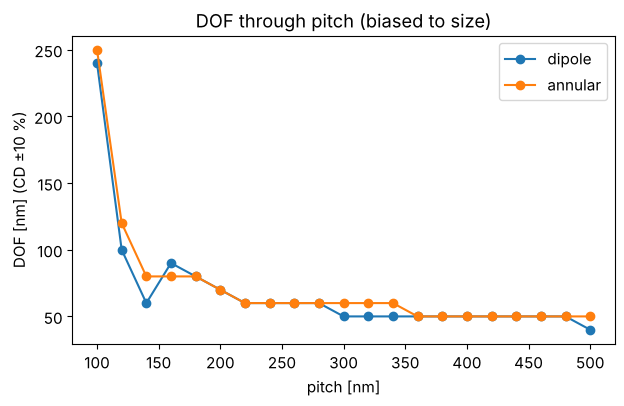

In [7]:
foci = np.linspace(-150, 150, 61)


def dof(sim, dose, cd=45.0, tolerance=0.1):
    # contiguous focus range around 0 with the CD in tolerance
    c = sim.fem(foci, [dose], THRESHOLD)[0]
    ok = np.abs(c - cd) <= tolerance*cd
    i = j = len(foci)//2
    if not ok[i]:
        return 0.0
    while i > 0 and ok[i - 1]:
        i -= 1
    while j < len(foci) - 1 and ok[j + 1]:
        j += 1
    return foci[j] - foci[i]


annular_1d = Illumination.annular(0.95, 0.7, n_samples=15, polarization="TE")
results = {}
for name, ill in (("dipole", dipole), ("annular", annular_1d)):
    sim = lines.with_(illumination=ill)
    b, d = opc.bias_table(sim, pitches, 45.0)
    results[name] = (b, d, [dof(sim.with_(layout=MaskLayout.lines_spaces(p, 45 + bb)), d)
                            for p, bb in zip(pitches, b)])

fig, ax = plt.subplots(figsize=(7, 4))
for name, (b, d, D) in results.items():
    ax.plot(pitches, D, "o-", label=name)
ax.set_xlabel("pitch [nm]"), ax.set_ylabel("DOF [nm] (CD ±10 %)")
ax.set_title("DOF through pitch (biased to size)"), ax.legend()
for name, (b, d, D) in results.items():
    print(name, dict(zip(pitches[:6], D[:6])), "... 500 nm:", D[-1])

The dipole gives a large DOF at the dense pitch, but drops to a minimum
at 140 nm pitch and partly recovers at 160 nm: a forbidden pitch. The
annular source does as well at the dense pitch here (45 nm lines at 100 nm
pitch are not yet at the limit where only a dipole prints them) and loses
DOF smoothly, without the dip. Beyond about 300 nm both are left with the DOF of an isolated
line, a few tens of nm.

**Sub-resolution assist features** (SRAFs, scattering bars) are narrow
lines next to a semi-dense or isolated line. They are too narrow to print,
but they diffract like the neighbours of a dense pattern, so the main line
images (and behaves through focus) more like a dense line. A simple rule:
bars of width $w$ at center distance $d$ (about the dense pitch) from the
line, up to three per side, as long as they keep a space $w$ to everything;
bars from both lines of a space that would collide are merged into one in
the middle. `insert_srafs()` implements this; the bias table is then
recomputed with the SRAFs in place (`make_layout`).

SRAFs per period: {160: 1, 180: 1, 200: 1, 220: 1, 240: 1, 260: 2, 280: 2, 300: 2, 320: 2, 340: 2, 360: 3, 380: 3, 400: 3, 420: 3, 440: 3, 460: 4, 480: 4, 500: 4}
SRAF margin (>0: does not print, focus -75..75 nm): {160: 0.01, 180: 0.02, 200: 0.08, 220: 0.27, 240: 0.31, 260: 0.08, 280: 0.2, 300: 0.25, 320: 0.3, 340: 0.35, 360: 0.19, 380: 0.25, 400: 0.28, 420: 0.35, 440: 0.45, 460: 0.23, 480: 0.26, 500: 0.28}


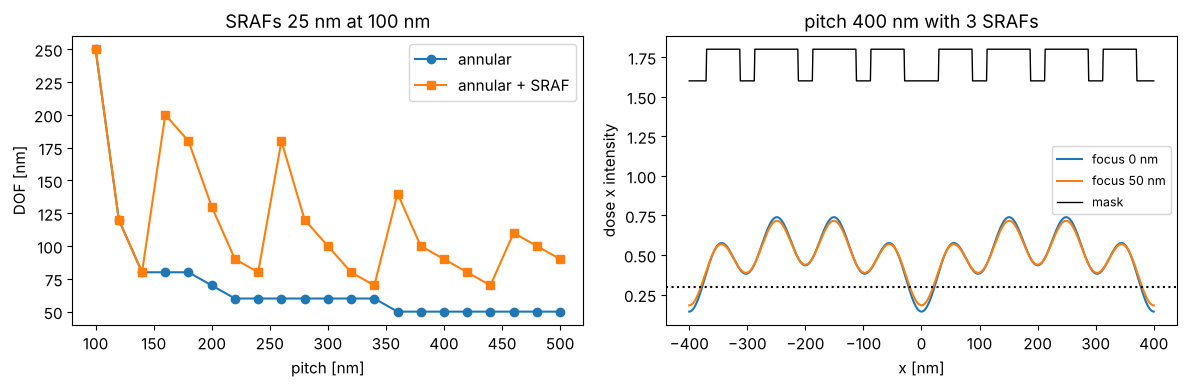

In [8]:
W_SRAF, D_SRAF = 25.0, 100.0


def with_srafs(pitch, cd):
    return opc.insert_srafs(MaskLayout.lines_spaces(pitch, cd), W_SRAF, D_SRAF, count=3)


sim_ann = lines.with_(illumination=annular_1d)
b_sraf, d_sraf = opc.bias_table(sim_ann, pitches, 45.0, make_layout=with_srafs)
D_sraf, margin = [], []
for p, b in zip(pitches, b_sraf):
    s = sim_ann.with_(layout=with_srafs(p, 45 + b))
    D_sraf.append(dof(s, d_sraf))
    margin.append(opc.sraf_margin(s, THRESHOLD, d_sraf, foci=(-75, 0, 75)))
n_sraf = [len(with_srafs(p, 45).features) - 1 for p in pitches]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(pitches, results["annular"][2], "o-", label="annular")
axs[0].plot(pitches, D_sraf, "s-", label="annular + SRAF")
axs[0].set_xlabel("pitch [nm]"), axs[0].set_ylabel("DOF [nm]"), axs[0].legend()
axs[0].set_title("SRAFs {:g} nm at {:g} nm".format(W_SRAF, D_SRAF))
L = with_srafs(400, 45 + b_sraf[list(pitches).index(400)])
x = np.linspace(-400, 400, 801)
for f in (0, 50):
    axs[1].plot(x, d_sraf*sim_ann.with_(layout=L).image(x, focus=f), label="focus {} nm".format(f))
axs[1].plot(x, 0.2*L.transmission(x, t_absorber=0).real + 1.6, "k", lw=1, label="mask")
axs[1].axhline(THRESHOLD, color="k", ls=":")
axs[1].set_xlabel("x [nm]"), axs[1].set_ylabel("dose x intensity"), axs[1].legend(fontsize=9)
axs[1].set_title("pitch 400 nm with {} SRAFs".format(len(L.features) - 1))
plt.tight_layout()
print("SRAFs per period:", {int(p): n for p, n in zip(pitches, n_sraf) if n})
print("SRAF margin (>0: does not print, focus -75..75 nm):",
      {int(p): round(m, 2) for p, m, n in zip(pitches, margin, n_sraf) if n})

Where they fit (from 160 nm pitch on), the SRAFs lift the DOF of the
semi-dense and isolated lines, while the image at their centers stays
above the threshold over ±75 nm of focus (`sraf_margin()` > 0). The
margin is smallest (1 to 2 %) at 160 and 180 nm pitch, where one bar sits
in the middle of a space of about 120 nm: a real rule deck would leave
these pitches without SRAFs or use narrower bars. The DOF
through pitch is not smooth: it depends on how many bars fit and where
(the rule could be refined per pitch, which is what SRAF rule tables do,
or placed by a model). Wider or more closely placed bars help more but
start to print; with the attenuated PSM the margin is small because even
narrow absorber lines are dark.

## 4. Model-based OPC

For 2D shapes the correction is computed with the imaging model:

- **Fragmentation**: every polygon edge is cut into fragments: short ones
  (`corner_length`) at the ends of an edge, the rest in pieces of at most
  `max_length`. Each fragment can move along its outward normal.
- **Sites and EPE**: every fragment has a site on the target edge where the
  edge placement error is measured: the distance from the target edge to
  the printed contour along the normal (positive: the feature prints too
  large). The image is computed once per iteration on a grid of one period
  and interpolated (periodic cubic splines) along the normals.
- **Iteration**: the moved polygons (with jogs between the fragments of an
  edge) are imaged again, until the EPEs are small.

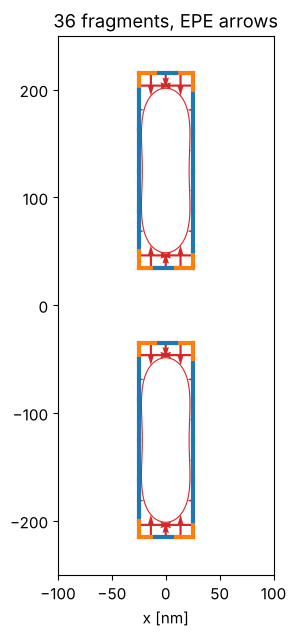

In [9]:
F = opc.FragmentedLayout(clips["tip to tip"], max_length=40, corner_length=15)
r = before["tip to tip"]
fig, ax = plt.subplots(figsize=(4, 7))
draw(ax, clips["tip to tip"].polygons, fill=False, ec="k", lw=1)
for k in range(len(F)):
    ax.plot(*np.array([F.start[k], F.end[k]]).T, "-", lw=3, color="C1" if F.corner[k] else "C0")
ax.quiver(*F.sites.T, *(F.normal*r.epe[:, None]).T, angles="xy", scale_units="xy", scale=1,
          color="C3", width=0.01)
ax.contour(r.x, r.y, r.image, [THRESHOLD], colors="C3", linewidths=0.8)
frame(ax, clips["tip to tip"], "{} fragments, EPE arrows".format(len(F)))

The blue fragments are moved by their EPE, the orange corner fragments
measure close to a corner whose printed rounding cannot be removed (their
sites sit at 3/4 of the fragment, away from the corner).

### Local correction against the Jacobian

The simplest iteration moves every fragment against its own EPE,
`offset -= damping*EPE` (`method="local"`). But fragments are much shorter
than the resolution: moving one changes the EPEs of its neighbours as
much as its own, and some combinations (alternating moves of neighbours)
change almost nothing. The local scheme then oscillates or produces jagged
masks.

`method="jacobian"` (the default) first measures the response of all EPEs
to every fragment move (the Jacobian $J$, a 2D MEEF matrix, by finite
differences of the target: one image per fragment), and then moves all
fragments together as the regularized least squares solution

$$\min_{\Delta}\; \lVert W(\mathrm{EPE} + J\Delta)\rVert^2 + \mu \lVert o + \Delta\rVert^2,$$

with $o$ the current offsets, weights $W$ (0.3 for the corner sites) and
$\mu$ a small fraction of the mean of $\mathrm{diag}(J^T W^2 J)$. The
regularization keeps the mask close to the target where the EPEs do not
care.

local   : max |EPE| 2.0 nm (without corner sites 2.0 nm), offsets -27 .. 30 nm
jacobian: max |EPE| 6.0 nm (without corner sites 0.6 nm), offsets 1 .. 9 nm


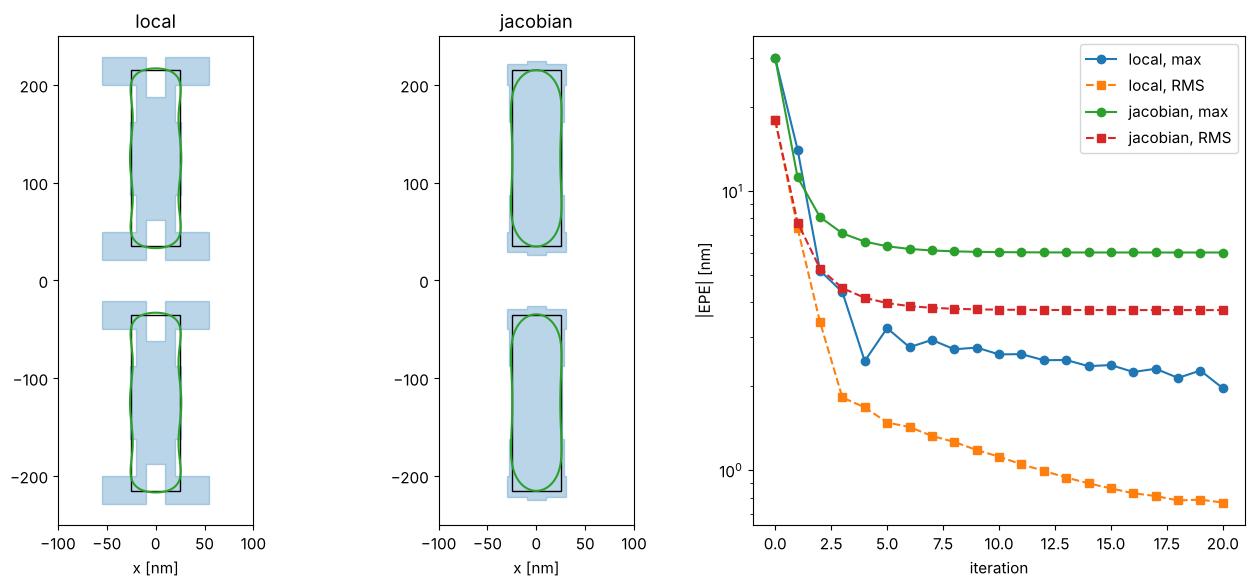

In [10]:
sim = sims["tip to tip"]
runs = {m: opc.model_opc(sim, dose=doses["tip to tip"], method=m, max_iter=20) for m in ("local", "jacobian")}

fig, axs = plt.subplots(1, 3, figsize=(13, 6), gridspec_kw={"width_ratios": [2, 2, 3]})
for ax, (m, r) in zip(axs, runs.items()):
    draw(ax, r.layout.polygons, fc="C0", alpha=0.3, ec="C0")
    draw(ax, clips["tip to tip"].polygons, fill=False, ec="k", lw=1)
    ax.contour(r.x, r.y, r.image, [THRESHOLD], colors="C2")
    frame(ax, clips["tip to tip"], m)
for m, r in runs.items():
    axs[2].semilogy(r.history[:, 0], "o-", label=m + ", max")
    axs[2].semilogy(r.history[:, 1], "s--", label=m + ", RMS")
axs[2].set_xlabel("iteration"), axs[2].set_ylabel("|EPE| [nm]"), axs[2].legend()
plt.tight_layout()
for m, r in runs.items():
    edge = ~r.fragments.corner
    print("{:8s}: max |EPE| {:.1f} nm (without corner sites {:.1f} nm), offsets {:.0f} .. {:.0f} nm".format(
        m, r.history[-1, 0], np.abs(r.epe[edge]).max(), r.offsets.min(), r.offsets.max()))

The local scheme reaches small EPEs at all sites, the corner sites
included, but only with an extreme mask: the corner fragments run into the
offset limit (30 nm), the middle of the line ends is pulled back between
them, and the iteration keeps creeping. Such a mask is hard to write and
very sensitive to mask errors. The Jacobian solution is smooth and small
(offsets of a few nm): a hammerhead at the line ends (the end and its
corners are moved out) and a small, even bias along the line. It trades
the EPE at the corner sites (6 nm, where the printed contour is round) for
a robust mask; the EPEs along the edges are below 1 nm.

### All clips

model-based OPC of the 4 clips: 0.9 s
            max |EPE|    RMS EPE  max |EPE| (edges)
tip to tip 30.0 ->  6.0 18.0 ->  3.8          0.6
L          30.0 ->  9.6 15.1 ->  3.7          1.4
T          30.0 -> 10.4 17.7 ->  4.7          1.3
contacts   14.9 -> 10.6  9.2 ->  6.1          2.3


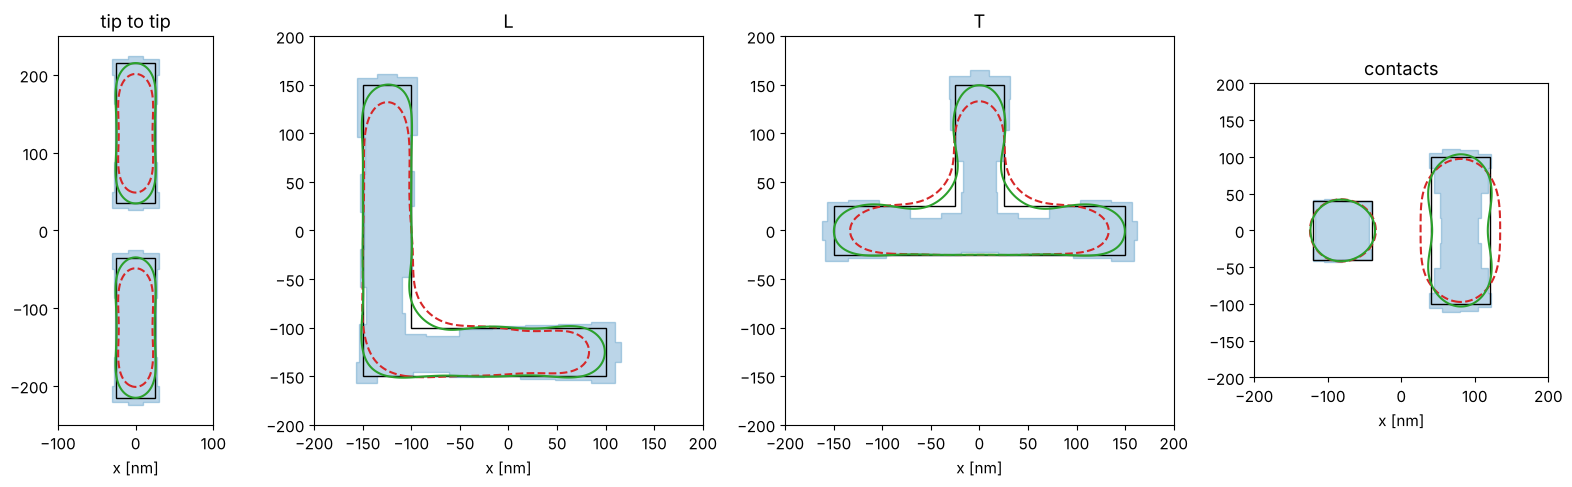

In [11]:
after = {}
t0 = time.time()
for name in clips:
    after[name] = opc.model_opc(sims[name], dose=doses[name])
print("model-based OPC of the 4 clips: {:.1f} s".format(time.time() - t0))

fig, axs = plt.subplots(1, 4, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 4, 4, 3]})
for ax, name in zip(axs, clips):
    draw(ax, after[name].layout.polygons, fc="C0", alpha=0.3, ec="C0")
    draw(ax, clips[name].polygons, fill=False, ec="k", lw=1)
    ax.contour(before[name].x, before[name].y, before[name].image, [THRESHOLD], colors="C3",
               linestyles="--")
    ax.contour(after[name].x, after[name].y, after[name].image, [THRESHOLD], colors="C2")
    frame(ax, clips[name], name)
plt.tight_layout()
print("{:10s} {:>10s} {:>10s} {:>18s}".format("", "max |EPE|", "RMS EPE", "max |EPE| (edges)"))
for name in clips:
    r0, r = before[name], after[name]
    edge = ~r.fragments.corner
    print("{:10s} {:4.1f} -> {:4.1f} {:4.1f} -> {:4.1f} {:12.1f}".format(
        name, r0.history[0, 0], r.history[-1, 0], r0.history[0, 1], r.history[-1, 1], np.abs(r.epe[edge]).max()))

Blue: corrected mask, black: target, red dashed: printed without OPC,
green: printed with OPC. The classic shapes appear by themselves:
hammerheads at the line ends, serifs on the outer corners, the inner
corners of the L and the T cut back, and a "dog bone" for the bar contact
(narrowed in the middle, widened at the ends). Along the edges the EPEs are
now 1 to 2 nm; the largest remaining errors sit at the corner sites, where the
printed contour has a radius of the order of $0.3\,\lambda/\mathrm{NA}$
that no Manhattan mask removes (the inner corners fill in, the outer
corners round off).

## 5. Speed: Abbe, Hopkins and SOCS

Every iteration needs a 2D image of the moved mask, and the Jacobian needs
one per fragment. With Abbe's method each image is a sum over all source
points. The Hopkins TCC of the target is computed once (it depends only on
the optics and the pitches) and every mask is then a quadratic form of its
spectrum; the SOCS approximation keeps only the leading kernels. For thin
masks the Hopkins image is exact.

In [12]:
name = "L"
timing = {}
for imager in ("abbe", "hopkins", "socs"):
    t0 = time.time()
    r = opc.model_opc(sims[name], dose=doses[name], imager=imager)
    timing[imager] = (time.time() - t0, r)
tcc = hopkins.TCC(sims[name])
socs = tcc.socs(energy=0.999)
print("orders: {}, SOCS kernels for 99.9 % of the energy: {}".format(len(tcc.m)*len(tcc.n), socs.n_kernels))
for imager, (t, r) in timing.items():
    print("{:8s} {:5.2f} s, max |EPE| {:.2f} nm, offsets differ from Hopkins by up to {:.2f} nm".format(
        imager, t, r.history[-1, 0], np.abs(r.offsets - timing["hopkins"][1].offsets).max()))

orders: 169, SOCS kernels for 99.9 % of the energy: 78
abbe      0.45 s, max |EPE| 9.64 nm, offsets differ from Hopkins by up to 0.00 nm
hopkins   0.25 s, max |EPE| 9.64 nm, offsets differ from Hopkins by up to 0.00 nm
socs      2.51 s, max |EPE| 9.65 nm, offsets differ from Hopkins by up to 0.07 nm


Hopkins and Abbe give the same correction (the images agree to rounding),
SOCS with 99.9 % of the energy differs by a fraction of a nm. Hopkins is
the fastest here; its advantage over Abbe grows with the number of source
points (the TCC is computed once). SOCS is slower for this clip: 99.9 % of
the energy needs 78 kernels for 169 orders, so it does not save anything
on a small grid. It pays off for large images with few kernels (a lower
energy fraction), which is how full chip OPC uses it.

## 6. Through focus

The correction is computed at best focus and the nominal dose. Through
focus the printed shape changes again: line ends are the most focus
sensitive part of a layout.

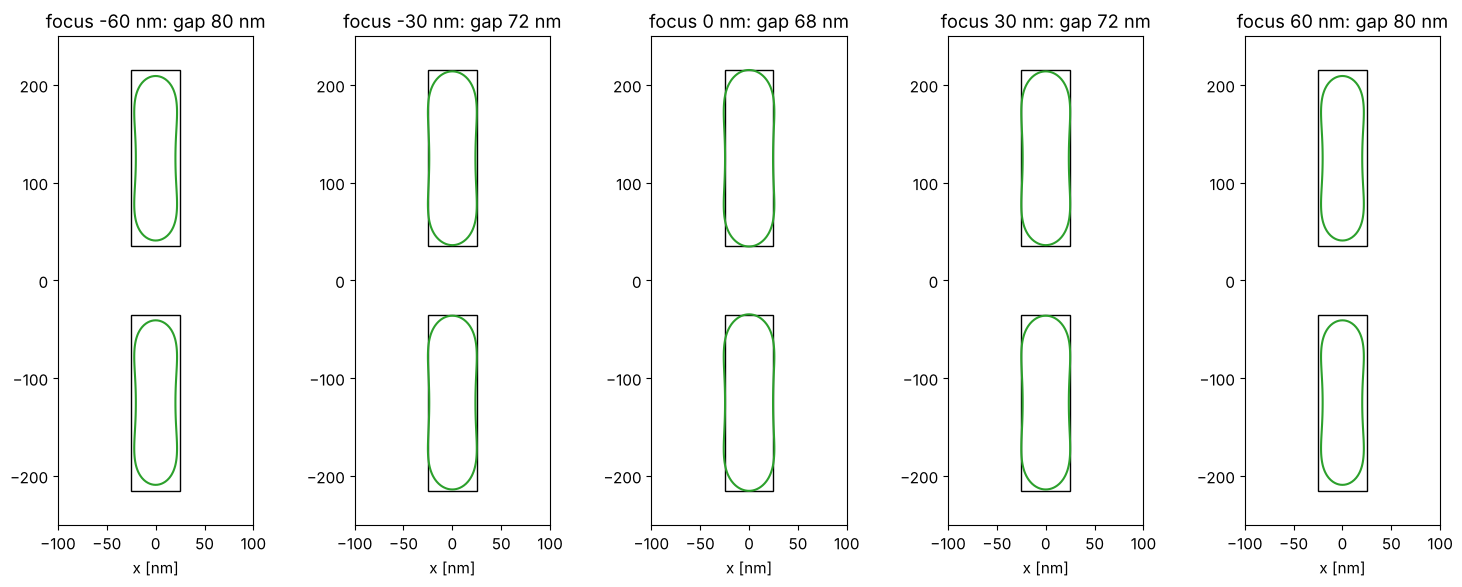

In [13]:
name = "tip to tip"
r = after[name]
sim_opc = sims[name].with_(layout=r.layout)
fig, axs = plt.subplots(1, 5, figsize=(15, 6))
for ax, f in zip(axs, (-60, -30, 0, 30, 60)):
    I = doses[name]*sim_opc.image(r.x, r.y, focus=f)
    draw(ax, clips[name].polygons, fill=False, ec="k", lw=1)
    ax.contour(r.x, r.y, I, [THRESHOLD], colors="C2")
    y = r.y[np.abs(r.y) < 60]
    cut = doses[name]*sim_opc.image([0.0], y, focus=f)[:, 0]
    gap = np.ptp(y[cut > THRESHOLD]) if np.any(cut > THRESHOLD) else 0.0
    frame(ax, clips[name], "focus {} nm: gap {:.0f} nm".format(f, gap))
plt.tight_layout()

The gap between the line ends (70 nm in the design) is on target at best
focus and opens up with defocus, to about 80 nm at 60 nm defocus, while
the line width changes much less. Production OPC therefore checks the result over a process
window (dose, focus, mask CD) and may trade nominal EPE for robustness;
here it is a matter of calling `model_opc()` with another `focus` or
`dose`, or checking the corrected mask with `LithoSimulation` as above.

## Summary

- `MaskLayout.from_polygons()`: Manhattan polygons as exact unions of
  rectangles, analytic diffraction orders, merging of overlaps.
- Rule-based OPC: `bias_table()` through pitch at a common dose; SRAFs by
  rule (`insert_srafs()`) with a printability check (`sraf_margin()`); the
  DOF through pitch shows the forbidden pitch of a dipole and the gain from
  SRAFs.
- Model-based OPC: `FragmentedLayout` (fragments, sites, moved polygons),
  `edge_placement_errors()` on a periodic image grid and `model_opc()`
  with the local or the regularized Jacobian update; Abbe, Hopkins or
  SOCS imaging.
- Not included: curvilinear masks and inverse lithography, resist models
  beyond the threshold, mask 3D effects in the 2D layouts (thin masks
  only), process window OPC, and the flow of a full chip (hierarchy,
  layout formats).